# UTS Praktikum Visi Komputer
## Tema 2 : Panorama Lingkungan Kampus
**Kelompok: 2**

### 1. Identitas Anggota Kelompok

| No | Nama Mahasiswa | NIM | Tahap Pipeline & Pembagian Tugas |
|:--:|:---|:---:|:---|
| 1 | **Abdan Syakura Bin yasir** | **2408107010014** | Tahap 1: Praproses Citra, Penyesuaian Kecerahan Channel V (HSV), & Histogram Equalization (Praktikum 3) |
| 2 | **Andre Alfaridzi** | **2408107010011** | Tahap 2: Ekstraksi Fitur (SIFT & ORB) serta Feature Matching dengan Lowe's Ratio Test (Praktikum 5) |
| 3 | **Rahmatul Uliya** | **2408107010012** | Tahap 3: Estimasi Matriks Homografi RANSAC & Multi-Image Warping Anchor Tengah (Praktikum 5) |
| 4 | **Nayla Nabila Syahel** | **2408107010005** | Tahap 4: Segmentasi & Pemotongan Batas Hitam Kontur (Praktikum 4) serta Evaluasi Seluruh Dataset |

---
> **Deskripsi Tugas Tema 2:**
> Menggabungkan 3–5 foto yang saling tumpang tindih (*overlap* 30–50%) menjadi satu citra panorama kampus yang rapi dan bebas dari batas hitam.
> 
> **Materi Wajib Praktikum yang Diterapkan:**

> - **Praktikum 3:** Konversi ruang warna (HSV, Grayscale), penyesuaian kecerahan saluran V, dan Histogram Equalization.
> - **Praktikum 4:** Deteksi kontur (`cv2.findContours`), `boundingRect`, dan pemangkasan batas hitam (*black border cropping*) otomatis.
> - **Praktikum 5:** Deteksi fitur SIFT dan ORB, Brute-Force Matcher dengan Lowe's Ratio Test, estimasi Homografi dengan RANSAC, dan `warpPerspective` multi-gambar.


---
## 2. Import dan Fungsi Bantu Pipeline

Pada bagian ini, seluruh pustaka yang diizinkan diimpor dan setiap tahapan pemrosesan visi komputer didefinisikan secara modular ke dalam fungsi-fungsi Python (P1):
- `baca_citra()`: Membaca file citra dan resize proporsional.
- `samakan_kecerahan()`: Penyesuaian kecerahan rata-rata berbasis saluran V pada ruang warna HSV.
- `praproses_gray_eq()`: Konversi ke Grayscale dan Histogram Equalization untuk pemerataan kontras.
- `deteksi()`: Ekstraksi keypoints dan deskriptor (SIFT / ORB).
- `matching()`: Pencocokan deskriptor menggunakan Brute-Force Matcher dan Lowe's Ratio Test.
- `estimasi_homografi()`: Estimasi matriks proyeksi planar 3x3 dengan algoritma robust RANSAC.
- `stitching_warping()`: Transformasi perspektif multi-citra dengan anchor tengah dan akumulasi blending.
- `segmentasi_kontur_crop()`: Segmentasi kontur biner terbesar untuk memotong area hitam kanvas secara otomatis.
- `visualisasi_matching()`: Visualisasi garis keterhubungan padanan inlier antar pasangan foto.


### Sel Kode 2.1: Import Library & Pengecekan Versi
Mengimpor modul pustaka standar OpenCV, NumPy, Matplotlib, OS, Time, CSV, dan Re, serta memastikan algoritma SIFT dan ORB terinisialisasi dengan baik.


In [1]:
import os
import time
import csv
import re
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("=== Inisialisasi Pustaka Visi Komputer ===")
print("OpenCV Version :", cv2.__version__)
print("NumPy Version  :", np.__version__)

# Verifikasi inisialisasi modul fitur SIFT dan ORB
sift_obj = cv2.SIFT_create()
orb_obj = cv2.ORB_create()
print("Detektor SIFT & ORB berhasil diinisialisasi!")


=== Inisialisasi Pustaka Visi Komputer ===
OpenCV Version : 5.0.0
NumPy Version  : 2.4.6
Detektor SIFT & ORB berhasil diinisialisasi!


### Sel Kode 2.2: Parameter Konfigurasi Global & Utility
Mendefinisikan parameter global pipeline yang digunakan di seluruh pengujian:
- `DATASET`: Deteksi otomatis folder dataset (`Dataset` atau `dataset`).
- `SISI_MAKS = 1000`: Ukuran sisi terpanjang citra setelah resize (sesuai instruksi soal 800–1200 px).
- `METODE_UTAMA = 'sift'`: Metode ekstraksi fitur utama.
- `RASIO = 0.75`: Nilai ambang batas Lowe's Ratio Test ($d_1 < 0.75 \times d_2$) untuk membuang false matches.
- `REPROJ = 4.0`: Ambang batas kesalahan reproyeksi RANSAC (dalam piksel).
- `MIN_GOOD = 15`: Jumlah minimal padanan lolos ratio test.
- `MIN_INLIER = 10`: Jumlah minimal inlier agar pasangan foto dianggap valid.


In [2]:
# Deteksi direktori dataset secara fleksibel (case-preserving)
DATASET = "Dataset" if os.path.isdir("Dataset") else "dataset"

SISI_MAKS = 1000      # Batas sisi terpanjang citra (piksel)
METODE_UTAMA = "sift" # Metode utama: 'sift' atau 'orb'
RASIO = 0.75          # Ambang batas Lowe's Ratio Test
REPROJ = 4.0          # Batas error reproyeksi RANSAC (piksel)
MIN_GOOD = 15         # Minimal good matches sebelum hitung homografi
MIN_INLIER = 10       # Minimal inlier RANSAC agar pasangan dinyatakan valid

def natural_sort_key(s):
    """Natural sorting agar urutan file numerik (1.jpg, 2.jpg... 10.jpg) terurut konsisten."""
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', s)]


### Sel Kode 2.3: Fungsi Tahap Praproses & Normalisasi Kecerahan (Praktikum 3)
1. `baca_citra`: Membaca citra dan memperkecil resolusi proporsional menggunakan interpolasi `cv2.INTER_AREA`.
2. `samakan_kecerahan`: Menghitung rata-rata intensitas saluran V (Value) pada HSV citra acuan pertama, lalu menyesuaikan gain saluran V foto lainnya.
3. `praproses_gray_eq`: Mengubah citra ke grayscale dan melakukan Histogram Equalization (`cv2.equalizeHist`) agar tekstur dan sudut lokal lebih menonjol.


In [3]:
def baca_citra(path, sisi_maks=SISI_MAKS):
    """Membaca file citra dan resize proporsional agar sisi terpanjang = sisi_maks."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"File citra tidak dapat dibaca: {path}")
    h, w = img.shape[:2]
    skala = sisi_maks / max(h, w)
    if skala < 1:
        img = cv2.resize(img, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    return img

def samakan_kecerahan(imgs):
    """
    Tahap Praproses Kecerahan:
    Menyamakan rata-rata intensitas Value (V) pada ruang warna HSV
    seluruh foto terhadap foto acuan pertama agar gradasi cahaya konsisten.
    """
    ref_val = cv2.cvtColor(imgs[0], cv2.COLOR_BGR2HSV)[:, :, 2].mean()
    hasil = []
    for im in imgs:
        hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV).astype(np.float32)
        gain = np.clip(ref_val / max(hsv[:, :, 2].mean(), 1.0), 0.7, 1.4)
        hsv[:, :, 2] = np.clip(hsv[:, :, 2] * gain, 0, 255)
        hasil.append(cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR))
    return hasil

def praproses_gray_eq(img):
    """Konversi ke Grayscale dan terapkan Histogram Equalization (Prak 3)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.equalizeHist(gray)


### Sel Kode 2.4: Fungsi Deteksi Fitur, Matching, & Homografi (Praktikum 5)
1. `deteksi`: Mengekstrak keypoints dan deskriptor fitur (SIFT berbasis gradient 128-D atau ORB berbasis binary BRIEF 256-bit).
2. `matching`: Pencocokan deskriptor menggunakan Brute-Force Matcher dengan metrik $L_2$ untuk SIFT dan Hamming untuk ORB, dilanjutkan Lowe's Ratio Test ($k=2$).
3. `estimasi_homografi`: Menghitung matriks homografi $3 \times 3$ yang memetakan titik citra A ke B menggunakan RANSAC untuk memfilter outlier.


In [4]:
def deteksi(gray, metode):
    """Tahap Deteksi: Mengekstrak keypoints dan deskriptor SIFT atau ORB."""
    if metode.lower() == "sift":
        det = cv2.SIFT_create()
    else:
        det = cv2.ORB_create(nfeatures=5000)
    return det.detectAndCompute(gray, None)

def matching(desA, desB, metode, rasio=RASIO):
    """
    Tahap Matching: Brute-Force Matcher dengan k-NN (k=2) dan Lowe's Ratio Test.
    Metrik jarak: NORM_L2 untuk deskriptor apung (SIFT) dan NORM_HAMMING untuk biner (ORB).
    """
    if desA is None or desB is None:
        return []
    norm = cv2.NORM_L2 if metode.lower() == "sift" else cv2.NORM_HAMMING
    bf = cv2.BFMatcher(norm)
    raw_matches = bf.knnMatch(desA, desB, k=2)
    return [m[0] for m in raw_matches if len(m) == 2 and m[0].distance < rasio * m[1].distance]

def estimasi_homografi(kpA, kpB, good, reproj=REPROJ):
    """
    Tahap Homografi: Estimasi matriks Homografi 3x3 menggunakan RANSAC robust.
    Mengembalikan matriks H ternormalisasi dan boolean inlier mask.
    """
    if len(good) < MIN_GOOD:
        return None, None
    ptsA = np.float32([kpA[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    ptsB = np.float32([kpB[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(ptsA, ptsB, cv2.RANSAC, reproj)
    if H is None:
        return None, None
    return H / H[2, 2], mask.ravel().astype(bool)


### Sel Kode 2.5: Fungsi Stitching (Warping) & Cropping Kontur (Praktikum 4 & 5)
1. `stitching_warping`: Menghubungkan seluruh citra dengan foto tengah ($r = n // 2$) sebagai acuan untuk menyeimbangkan distorsi akumulatif. Melakukan proyeksi koordinat 4 sudut dan warping akumulatif ke kanvas bersama.
2. `segmentasi_kontur_crop`: Mendeteksi kontur non-hitam terbesar (`cv2.findContours`) pada mask hasil transformasi perspektif, mengambil bounding rectangle, dan memangkas batas hitam secara iteratif.


In [5]:
def stitching_warping(imgs, pasangan):
    """
    Tahap Stitching & Warping:
    Menggabungkan rangkaian citra ke bidang proyeksi bersama dengan foto tengah
    (r = n // 2) sebagai anchor acuan agar distorsi kumulatif ke kiri dan kanan seimbang.
    """
    n = len(imgs)
    r = n // 2
    Hs = [None] * n
    Hs[r] = np.eye(3)
    
    # Rantai homografi ke arah kanan
    for i in range(r + 1, n):
        if pasangan[i]["H"] is None:
            return None, None
        Hs[i] = Hs[i - 1] @ pasangan[i]["H"]
        
    # Rantai homografi ke arah kiri (menggunakan invers matriks)
    for i in range(r - 1, -1, -1):
        if pasangan[i + 1]["H"] is None:
            return None, None
        Hs[i] = Hs[i + 1] @ np.linalg.inv(pasangan[i + 1]["H"])
        
    # Menghitung batas ukuran kanvas panorama terpadu
    sudut = []
    for im, H in zip(imgs, Hs):
        h, w = im.shape[:2]
        c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        sudut.append(cv2.perspectiveTransform(c, H))
    sem = np.concatenate(sudut)
    xmin, ymin = np.floor(sem.min(axis=0).ravel()).astype(int)
    xmax, ymax = np.ceil(sem.max(axis=0).ravel()).astype(int)
    W, Ht = int(xmax - xmin), int(ymax - ymin)
    
    if W <= 0 or Ht <= 0 or W * Ht > 16_000_000:
        return None, None
        
    T = np.array([[1, 0, -xmin], [0, 1, -ymin], [0, 0, 1]], np.float64)
    acc = np.zeros((Ht, W, 3), np.float32)
    cnt = np.zeros((Ht, W), np.float32)
    
    for im, H in zip(imgs, Hs):
        M = T @ H
        warp = cv2.warpPerspective(im, M, (W, Ht))
        m = cv2.warpPerspective(np.full(im.shape[:2], 255, np.uint8), M, (W, Ht))
        m = cv2.erode(m, np.ones((3, 3), np.uint8)) > 0
        acc[m] += warp[m]
        cnt[m] += 1
        
    pano = (acc / np.maximum(cnt, 1)[..., None]).astype(np.uint8)
    return pano, cnt > 0

def segmentasi_kontur_crop(pano, mask):
    """
    Tahap Segmentasi & Cropping:
    Menemukan kontur terluar dari mask biner citra non-hitam (Praktikum 4),
    mengekstrak boundingRect, lalu memangkas sisi yang masih mengandung piksel hitam.
    """
    biner = mask.astype(np.uint8) * 255
    cnts, _ = cv2.findContours(biner, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return pano, mask
    c = max(cnts, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    sub = mask[y:y + h, x:x + w]
    t, b, l, r = 0, h, 0, w
    
    while b - t > 1 and r - l > 1:
        s = sub[t:b, l:r]
        hitam = {
            "atas": int((~s[0]).sum()),
            "bawah": int((~s[-1]).sum()),
            "kiri": int((~s[:, 0]).sum()),
            "kanan": int((~s[:, -1]).sum())
        }
        sisi, n = max(hitam.items(), key=lambda kv: kv[1])
        if n == 0:
            break
        if sisi == "atas": t += 1
        elif sisi == "bawah": b -= 1
        elif sisi == "kiri": l += 1
        else: r -= 1
        
    pano_crop = pano[y + t:y + b, x + l:x + r]
    return pano_crop, (x + l, y + t, r - l, b - t)


### Sel Kode 2.6: Fungsi Pembantu Visualisasi (Praktikum 2)
Mendefinisikan fungsi visualisasi citra dengan Matplotlib:
- `tampil()`: Menampilkan gambar tunggal dengan konversi warna BGR ke RGB.
- `visualisasi_matching()`: Menggambar padanan keypoint dan garis inlier antar pasangan citra.


In [6]:
def tampil(img, judul="", ukuran=(12, 6)):
    """Menampilkan citra BGR ke RGB menggunakan matplotlib (Praktikum 2)."""
    plt.figure(figsize=ukuran)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(judul, fontsize=12, fontweight="bold")
    plt.axis("off")
    plt.show()

def visualisasi_matching(img_kanan, kpA, img_kiri, kpB, good, inlier_mask, judul=""):
    """Visualisasi keypoints dan garis padanan inlier antar pasangan citra."""
    if inlier_mask is not None:
        good_in = [m for m, k in zip(good, inlier_mask) if k]
    else:
        good_in = good
    match_img = cv2.drawMatches(img_kanan, kpA, img_kiri, kpB, good_in[:70], None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return match_img


---
## 3. Memuat Dataset dan Ground Truth (Materi Praktikum 2)

Sesuai aturan soal UTS:
1. Membaca file anotasi `ground_truth.csv` dari folder dataset.
2. Memuat seluruh citra per lokasi dengan pengurutan numerik teratur (*left to right*).
3. **Menampilkan contoh 1 citra per kondisi** (*ideal, cahaya, sudut, sulit*) dalam satu figure Matplotlib (P2).


### Sel Kode 3.1: Membaca Ground Truth dan Mengelompokkan Citra per Lokasi
Membaca file `ground_truth.csv`, mengurutkan citra, dan menampilkan ringkasan seluruh lokasi yang berhasil dimuat.


In [7]:
def baca_gt(path=os.path.join(DATASET, "ground_truth.csv")):
    """Membaca file ground_truth.csv."""
    if not os.path.exists(path):
        path = "ground_truth.csv"
    with open(path, newline="", encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

def muat_per_lokasi(gt):
    """Memuat seluruh citra per lokasi sesuai urutan pada ground_truth.csv."""
    kelompok = {}
    for r in gt:
        kelompok.setdefault(r["lokasi"], []).append(r)
    hasil = {}
    for nama, baris in kelompok.items():
        baris.sort(key=lambda r: int(r["urutan"]))
        imgs = [baca_citra(os.path.join(DATASET, nama, r["file"])) for r in baris]
        hasil[nama] = dict(
            imgs=imgs,
            kondisi=baris[0]["kondisi"],
            keterangan=baris[0]["keterangan"],
            files=[r["file"] for r in baris]
        )
    return hasil

gt = baca_gt()
lokasi_data = muat_per_lokasi(gt)

print(f"Dataset berhasil dimuat dari '{DATASET}' (Total Lokasi: {len(lokasi_data)}, Total Foto: {len(gt)}):")
for nama, info in lokasi_data.items():
    print(f"  - {nama:<9} | Kondisi: {info['kondisi']:<7} | Jumlah Foto: {len(info['imgs'])} | Keterangan: {info['keterangan']}")


FileNotFoundError: [Errno 2] No such file or directory: 'ground_truth.csv'

### Sel Kode 3.2: Visualisasi Contoh 1 Citra per Kondisi (Syarat Rubrik P2)
Menampilkan 1 contoh citra untuk masing-masing 4 kondisi variasi:
- **IDEAL:** Pencahayaan terang merata dan overlap konsisten (Lokasi 1).
- **CAHAYA:** Variasi gradasi bayangan dan pencahayaan lampu ruangan (Lokasi 3).
- **SUDUT:** Variasi rotasi sudut pandang lebar 5 foto (Lokasi 2).
- **SULIT:** Pemandangan kompleks luas dengan pohon, gedung, dan rentang sudut ekstrem (Lokasi 4).


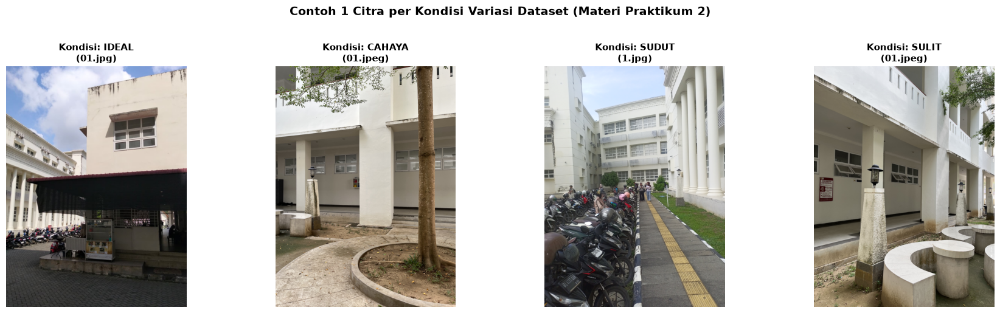

In [ ]:
kondisi_list = ["ideal", "cahaya", "sudut", "sulit"]
fig, axs = plt.subplots(1, 4, figsize=(18, 5))

for ax, k in zip(axs, kondisi_list):
    contoh_lok = next((info for info in lokasi_data.values() if info["kondisi"] == k), None)
    if contoh_lok:
        img_contoh = contoh_lok["imgs"][0]
        ax.imshow(cv2.cvtColor(img_contoh, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Kondisi: {k.upper()}\n({contoh_lok['files'][0]})", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Contoh 1 Citra per Kondisi Variasi Dataset (Materi Praktikum 2)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 4. Pipeline Langkah demi Langkah (Demo pada Lokasi 1)

Pada bagian ini, pipeline dijalankan secara terperinci tahap demi tahap pada **Lokasi 1** (Kondisi Ideal) untuk memperlihatkan citra hasil antara (*intermediate results*):
$$\text{Asli} \xrightarrow{\text{HSV}} \text{Kecerahan Sama} \xrightarrow{\text{HistEq}} \text{Gray Equalize} \xrightarrow{\text{SIFT/ORB}} \text{Keypoints} \xrightarrow{\text{BFMatcher}} \text{Inliers} \xrightarrow{\text{Warp}} \text{Pano Mentah} \xrightarrow{\text{Kontur}} \text{Hasil Akhir}$$

Setiap tahap disertai sel markdown singkat yang menjelaskan alasan pemilihan metode dan parameternya.


### Sel Kode 4.1: Tahap 1 & 2 - Normalisasi Kecerahan & Grayscale Histogram Equalization
- **Alasan Pemilihan Saluran V (HSV):** Penyesuaian intensitas dilakukan pada channel V (Value) agar rona warna asli (Hue dan Saturation) tidak terdistorsi.
- **Alasan Grayscale + Histogram Equalization:** Pemerataan kurva histogram meningkatkan kontras lokal pada area berpencahayaan rendah, sehingga detektor fitur dapat menemukan lebih banyak sudut dan gradien tepi yang konsisten.


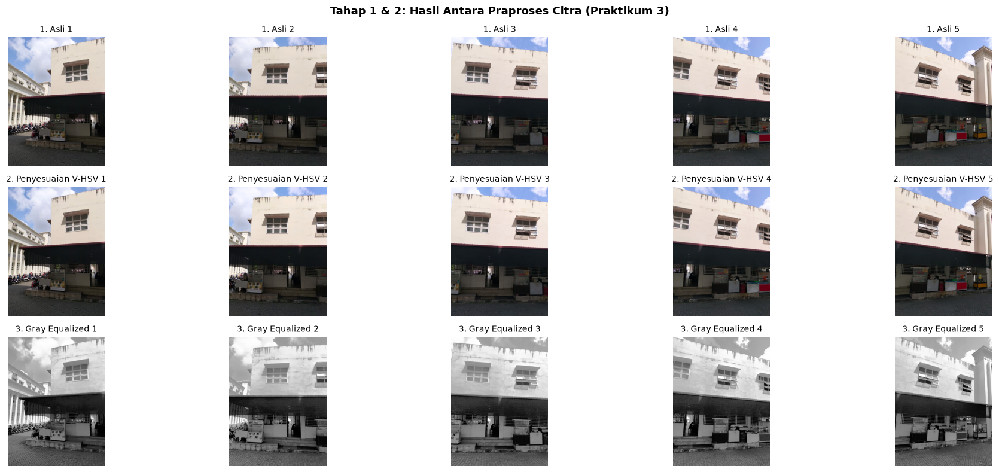

In [ ]:
demo_imgs_asli = lokasi_data["lokasi1"]["imgs"]
demo_imgs_terang = samakan_kecerahan(demo_imgs_asli)
demo_gray_eq = [praproses_gray_eq(im) for im in demo_imgs_terang]

n = len(demo_imgs_asli)
fig, axs = plt.subplots(3, n, figsize=(4 * n, 8), squeeze=False)
for j in range(n):
    axs[0][j].imshow(cv2.cvtColor(demo_imgs_asli[j], cv2.COLOR_BGR2RGB))
    axs[0][j].set_title(f"1. Asli {j+1}", fontsize=10)
    axs[1][j].imshow(cv2.cvtColor(demo_imgs_terang[j], cv2.COLOR_BGR2RGB))
    axs[1][j].set_title(f"2. Penyesuaian V-HSV {j+1}", fontsize=10)
    axs[2][j].imshow(demo_gray_eq[j], cmap="gray")
    axs[2][j].set_title(f"3. Gray Equalized {j+1}", fontsize=10)
    for row in range(3):
        axs[row][j].axis("off")

plt.suptitle("Tahap 1 & 2: Hasil Antara Praproses Citra (Praktikum 3)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### Sel Kode 4.2: Tahap 3 & 4 - Deteksi Keypoints & Pencocokan Fitur (Inliers RANSAC)
- **Alasan SIFT:** Menggunakan Difference-of-Gaussians (DoG) dan deskriptor gradien 128-D yang invarian terhadap rotasi, skala, dan translasi.
- **Alasan Lowe's Ratio Test ($0.75$):** Menolak titik pencocokan semu (*ambiguous false matches*) yang memiliki kemiripan jarak hampir sama dengan tetangga kedua.
- **Alasan RANSAC:** Mengeliminasi outlier secara iteratif sehingga matriks homografi $3 \times 3$ yang dihitung hanya didasarkan pada pasangan inlier sejati.


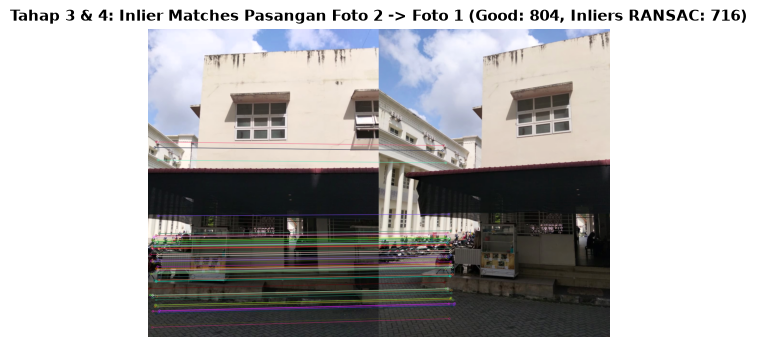

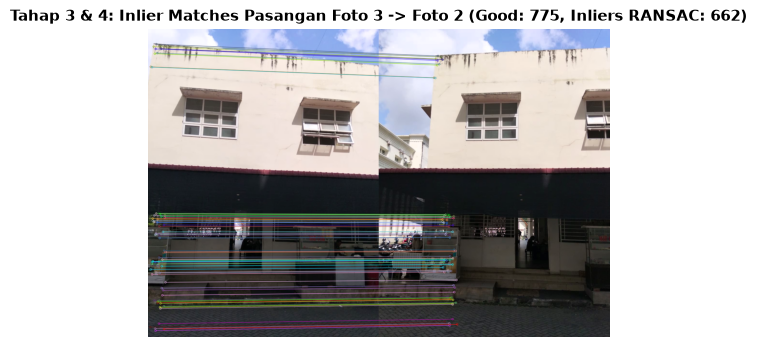

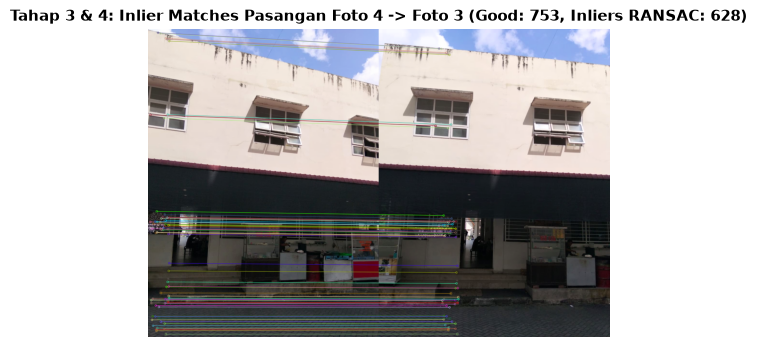

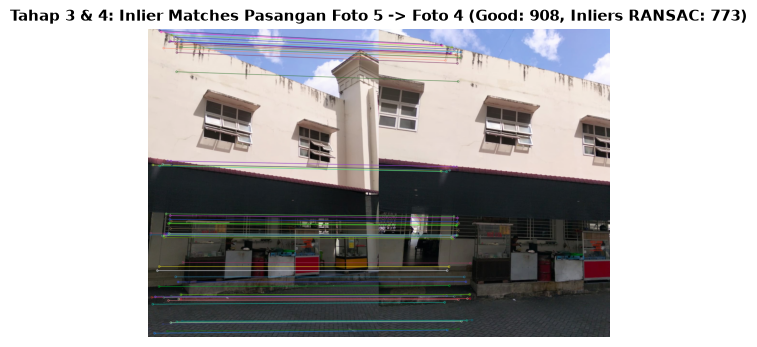

In [ ]:
demo_fitur = [deteksi(g, METODE_UTAMA) for g in demo_gray_eq]
demo_pasangan = [None]

for i in range(1, n):
    kpA, desA = demo_fitur[i]
    kpB, desB = demo_fitur[i - 1]
    good = matching(desA, desB, METODE_UTAMA)
    H, inl = estimasi_homografi(kpA, kpB, good)
    demo_pasangan.append(dict(
        kpA=kpA, kpB=kpB, good=good, H=H, inlier=inl,
        n_inlier=int(inl.sum()) if inl is not None else 0
    ))
    
    # Tampilkan visualisasi matching
    match_vis = visualisasi_matching(demo_imgs_terang[i], kpA, demo_imgs_terang[i-1], kpB, good, inl)
    plt.figure(figsize=(15, 4))
    plt.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
    plt.title(f"Tahap 3 & 4: Inlier Matches Pasangan Foto {i+1} -> Foto {i} (Good: {len(good)}, Inliers RANSAC: {demo_pasangan[i]['n_inlier']})", fontsize=11, fontweight="bold")
    plt.axis("off")
    plt.show()


### Sel Kode 4.3: Tahap 5 & 6 - Multi-Image Warping & Cropping Kontur Sisi Hitam
- **Alasan Anchor Tengah ($r = n // 2$):** Membagi proyeksi transformasi ke kiri dan kanan secara seimbang, sehingga distorsi geometris ujung kanvas berkurang drastis dibandingkan jika menggunakan foto pertama sebagai acuan.
- **Alasan Cropping Kontur (Praktikum 4):** Menemukan bentuk poligon luar hasil transformasi dengan `findContours` dan `boundingRect`, lalu memotong sisa sisi hitam secara iteratif tanpa menghilangkan area citra utama.


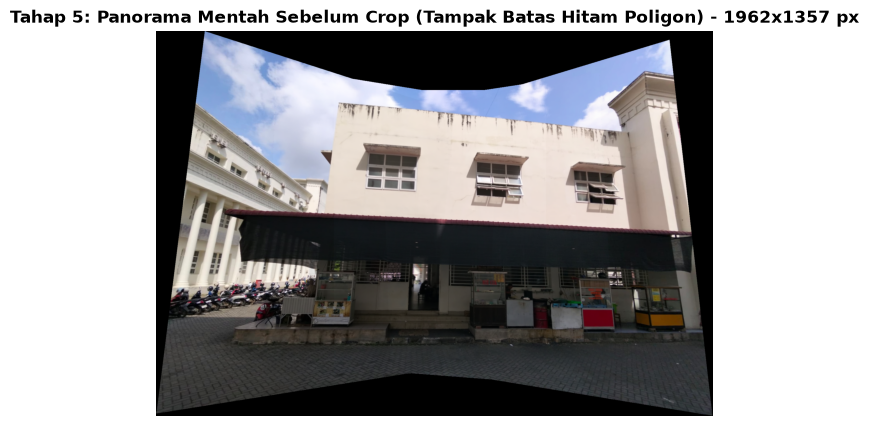

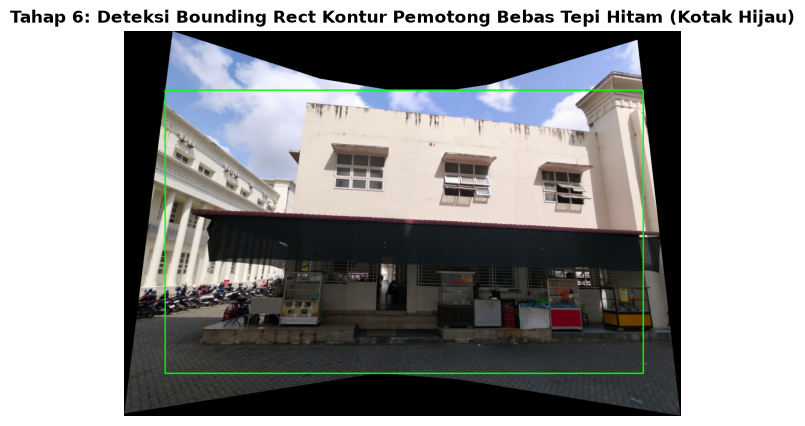

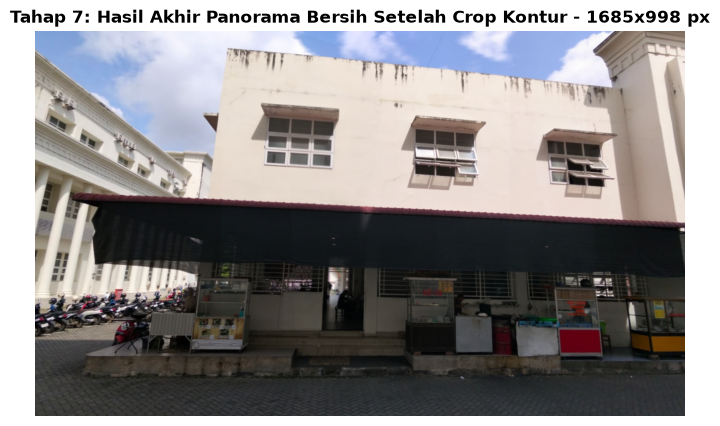

In [ ]:
demo_pano_mentah, demo_mask = stitching_warping(demo_imgs_terang, demo_pasangan)
demo_pano_crop, crop_bbox = segmentasi_kontur_crop(demo_pano_mentah, demo_mask)

# Visualisasi panorama mentah vs sesudah crop
tampil(demo_pano_mentah, f"Tahap 5: Panorama Mentah Sebelum Crop (Tampak Batas Hitam Poligon) - {demo_pano_mentah.shape[1]}x{demo_pano_mentah.shape[0]} px", (14, 5))

# Visualisasi bounding box pemotongan kontur
x, y, w, h = crop_bbox
demo_bbox_vis = demo_pano_mentah.copy()
cv2.rectangle(demo_bbox_vis, (x, y), (x + w, y + h), (0, 255, 0), 4)
tampil(demo_bbox_vis, f"Tahap 6: Deteksi Bounding Rect Kontur Pemotong Bebas Tepi Hitam (Kotak Hijau)", (14, 5))

tampil(demo_pano_crop, f"Tahap 7: Hasil Akhir Panorama Bersih Setelah Crop Kontur - {demo_pano_crop.shape[1]}x{demo_pano_crop.shape[0]} px", (14, 5))


---
## 5. Evaluasi Pipeline ke Seluruh Dataset & Penyimpanan Output per Langkah

Pada bagian ini, pipeline lengkap dijalankan secara otomatis ke **seluruh 6 lokasi dataset** dengan metode SIFT dan ORB.

**Struktur Output Sesuai Lokasi:**
Setiap lokasi dibuatkan foldernya masing-masing di dalam `output/{lokasi}/`, dan **seluruh hasil proses per langkah disimpan secara lengkap**:
- `01_asli_*.jpg` : Citra input yang telah di-resize
- `02_kecerahan_*.jpg` : Citra setelah penyesuaian kecerahan saluran V (HSV)
- `03_gray_equalize_*.jpg` : Citra hasil Grayscale Histogram Equalization
- `04_keypoints_*.jpg` : Visualisasi sebaran keypoints pada setiap foto
- `05_matching_pair_*.jpg` : Visualisasi garis inlier matches antar pasangan foto
- `06_pano_mentah_*.jpg` : Panorama mentah sebelum crop (memperlihatkan bidang transformasi)
- `07_mask_kontur_*.jpg` : Visualisasi deteksi kontur biner pemotong area hitam
- `08_panorama_final_*.jpg` : Panorama akhir yang rapi dan bersih


### Sel Kode 5.1: Eksekusi Pipeline End-to-End & Penyimpanan Hasil Proses per Langkah
Fungsi `proses_dan_simpan_lokasi()` menjalankan seluruh tahapan pipeline untuk setiap lokasi, menyimpan seluruh hasil antara dan hasil akhir ke `output/{lokasi}/`, serta mengembalikan metrik evaluasi lengkap.


In [ ]:
os.makedirs("output", exist_ok=True)

def proses_dan_simpan_lokasi(nama_lokasi, info_lokasi, metode):
    """
    Menjalankan seluruh tahapan pipeline visi komputer, menyimpan seluruh citra
    hasil proses langkah demi langkah ke dalam folder 'output/{nama_lokasi}/',
    dan mengembalikan metrik evaluasi.
    """
    t0 = time.perf_counter()
    lok_folder = os.path.join("output", nama_lokasi)
    os.makedirs(lok_folder, exist_ok=True)
    
    imgs_asli = info_lokasi["imgs"]
    n_foto = len(imgs_asli)
    
    # Simpan Tahap 1: Citra Asli
    for idx, im in enumerate(imgs_asli):
        cv2.imwrite(os.path.join(lok_folder, f"01_asli_{idx+1}.jpg"), im)
        
    # Tahap 2: Penyesuaian Kecerahan
    imgs_terang = samakan_kecerahan(imgs_asli)
    for idx, im in enumerate(imgs_terang):
        cv2.imwrite(os.path.join(lok_folder, f"02_kecerahan_{idx+1}.jpg"), im)
        
    # Tahap 3: Grayscale + Histogram Equalization
    imgs_gray = [praproses_gray_eq(im) for im in imgs_terang]
    for idx, im in enumerate(imgs_gray):
        cv2.imwrite(os.path.join(lok_folder, f"03_gray_equalize_{idx+1}.jpg"), im)
        
    # Tahap 4: Deteksi Keypoints SIFT/ORB
    fitur = [deteksi(g, metode) for g in imgs_gray]
    for idx, (kp, des) in enumerate(fitur):
        kp_vis = cv2.drawKeypoints(imgs_terang[idx], kp, None, color=(0, 255, 0))
        cv2.imwrite(os.path.join(lok_folder, f"04_keypoints_{metode}_{idx+1}.jpg"), kp_vis)
        
    # Tahap 5: Matching & Estimasi Homografi RANSAC
    pasangan = [None]
    for i in range(1, n_foto):
        kpA, desA = fitur[i]
        kpB, desB = fitur[i - 1]
        good = matching(desA, desB, metode)
        H, inl = estimasi_homografi(kpA, kpB, good)
        pasangan.append(dict(
            kpA=kpA, kpB=kpB, good=good, H=H, inlier=inl,
            n_inlier=int(inl.sum()) if inl is not None else 0
        ))
        # Simpan visualisasi matching
        match_vis = visualisasi_matching(imgs_terang[i], kpA, imgs_terang[i-1], kpB, good, inl)
        cv2.imwrite(os.path.join(lok_folder, f"05_matching_pair_{i}_{i+1}_{metode}.jpg"), match_vis)
        
    # Verifikasi keberhasilan seluruh pasangan
    valid = all(p["H"] is not None and p["n_inlier"] >= MIN_INLIER for p in pasangan[1:])
    pano_mentah = pano_crop = None
    bbox = None
    
    if valid:
        try:
            # Tahap 6: Stitching & Warping
            pano_mentah, mask = stitching_warping(imgs_terang, pasangan)
            if pano_mentah is not None:
                cv2.imwrite(os.path.join(lok_folder, f"06_pano_mentah_{metode}.jpg"), pano_mentah)
                # Tahap 7 & 8: Segmentasi Kontur & Pemotongan Sisi Hitam
                pano_crop, bbox = segmentasi_kontur_crop(pano_mentah, mask)
                
                # Simpan visualisasi bounding box kontur
                x, y, w, h = bbox
                vis_mask_kontur = pano_mentah.copy()
                cv2.rectangle(vis_mask_kontur, (x, y), (x + w, y + h), (0, 255, 0), 4)
                cv2.imwrite(os.path.join(lok_folder, f"07_mask_kontur_{metode}.jpg"), vis_mask_kontur)
                
                # Simpan hasil akhir panorama bersih
                cv2.imwrite(os.path.join(lok_folder, f"08_panorama_final_{metode}.jpg"), pano_crop)
                # Salinan pada root output
                cv2.imwrite(os.path.join("output", f"panorama_{nama_lokasi}_{metode}.jpg"), pano_crop)
        except Exception as e:
            pano_mentah = pano_crop = None
            
    durasi = time.perf_counter() - t0
    return dict(
        metode=metode, imgs=imgs_asli, fitur=fitur, pasangan=pasangan,
        valid=bool(valid and pano_crop is not None),
        pano_mentah=pano_mentah, pano=pano_crop, waktu=durasi,
        n_kp=[len(f[0]) for f in fitur]
    )

hasil_evaluasi = {}
print("=== Menjalankan Pipeline & Menyimpan Hasil Proses per Langkah ke Seluruh Lokasi ===")
for nama, info in lokasi_data.items():
    for met in ("sift", "orb"):
        hasil_evaluasi[(nama, met)] = proses_dan_simpan_lokasi(nama, info, met)
        v = hasil_evaluasi[(nama, met)]["valid"]
        w = hasil_evaluasi[(nama, met)]["waktu"]
        print(f"  > [{nama:<9}] {met.upper():<5} -> Status: {'SUKSES' if v else 'GAGAL'} | Waktu: {w:.2f}s | Output: output/{nama}/")
print("Semua proses per langkah berhasil disimpan di folder masing-masing lokasi!")


=== Menjalankan Pipeline & Menyimpan Hasil Proses per Langkah ke Seluruh Lokasi ===
  > [lokasi1  ] SIFT  -> Status: SUKSES | Waktu: 0.97s | Output: output/lokasi1/
  > [lokasi1  ] ORB   -> Status: SUKSES | Waktu: 0.75s | Output: output/lokasi1/
  > [lokasi2  ] SIFT  -> Status: SUKSES | Waktu: 1.24s | Output: output/lokasi2/
  > [lokasi2  ] ORB   -> Status: SUKSES | Waktu: 0.77s | Output: output/lokasi2/
  > [lokasi3  ] SIFT  -> Status: SUKSES | Waktu: 0.62s | Output: output/lokasi3/
  > [lokasi3  ] ORB   -> Status: SUKSES | Waktu: 0.42s | Output: output/lokasi3/
  > [lokasi4  ] SIFT  -> Status: SUKSES | Waktu: 1.58s | Output: output/lokasi4/
  > [lokasi4  ] ORB   -> Status: SUKSES | Waktu: 1.16s | Output: output/lokasi4/
  > [lokasi5  ] SIFT  -> Status: SUKSES | Waktu: 0.73s | Output: output/lokasi5/
  > [lokasi5  ] ORB   -> Status: SUKSES | Waktu: 0.46s | Output: output/lokasi5/
  > [lokasi6  ] SIFT  -> Status: SUKSES | Waktu: 1.04s | Output: output/lokasi6/
  > [lokasi6  ] ORB   -> 

### Sel Kode 5.2: Tabel Hasil Evaluasi Pasangan Citra & Akurasi per Kondisi
Menampilkan tabel rincian performa setiap pasangan citra berurutan (keypoints A & B, good matches, inliers RANSAC, rasio inlier, status), serta menghitung persentase keberhasilan per kondisi variasi.


In [ ]:
print("=" * 82)
print(f"{'Lokasi':<10}{'Kondisi':<9}{'Pasangan':<10}{'kpA':>6}{'kpB':>6}{'Good':>6}{'Inlier':>8}{'Rasio':>7}  Status")
print("=" * 82)

for nama, info in lokasi_data.items():
    h = hasil_evaluasi[(nama, METODE_UTAMA)]
    for i in range(1, len(h["imgs"])):
        p = h["pasangan"][i]
        rasio = p["n_inlier"] / len(p["good"]) if p["good"] else 0
        ok = p["H"] is not None and p["n_inlier"] >= MIN_INLIER
        print(f"{nama:<10}{info['kondisi']:<9}{f'{i+1}->{i}':<10}{len(p['kpA']):>6}{len(p['kpB']):>6}"
              f"{len(p['good']):>6}{p['n_inlier']:>8}{rasio:>7.2f}  {'OK' if ok else 'GAGAL'}")

print("=" * 82)
print(f"\nRekapitulasi Akurasi Pipeline per Kondisi Variasi (Metode: {METODE_UTAMA.upper()}):")
print("-" * 72)
for k in sorted(set(i["kondisi"] for i in lokasi_data.values())):
    nama_k = [n for n, i in lokasi_data.items() if i["kondisi"] == k]
    sukses = sum(hasil_evaluasi[(n, METODE_UTAMA)]["valid"] for n in nama_k)
    psg = [p for n in nama_k for p in hasil_evaluasi[(n, METODE_UTAMA)]["pasangan"][1:]]
    psg_ok = sum(p["H"] is not None and p["n_inlier"] >= MIN_INLIER for p in psg)
    print(f"Kondisi {k.upper():<7}: Panorama Berhasil = {sukses}/{len(nama_k)} ({100*sukses/len(nama_k):.1f}%) | "
          f"Pasangan Berhasil = {psg_ok}/{len(psg)} ({100*psg_ok/len(psg):.1f}%)")
print("-" * 72)


Lokasi    Kondisi  Pasangan     kpA   kpB  Good  Inlier  Rasio  Status
lokasi1   ideal    2->1        3667  4020   804     716   0.89  OK
lokasi1   ideal    3->2        3580  3667   775     662   0.85  OK
lokasi1   ideal    4->3        3909  3580   753     628   0.83  OK
lokasi1   ideal    5->4        4039  3909   908     773   0.85  OK
lokasi2   sudut    2->1        4468  3373  1147     839   0.73  OK
lokasi2   sudut    3->2        5243  4468  1519    1119   0.74  OK
lokasi2   sudut    4->3        6926  5243  1379     795   0.58  OK
lokasi2   sudut    5->4        6477  6926  2380    2024   0.85  OK
lokasi3   cahaya   2->1        4603  4829  1047     565   0.54  OK
lokasi3   cahaya   3->2        4411  4603   943     460   0.49  OK
lokasi4   sulit    2->1        3925  2737   633     402   0.64  OK
lokasi4   sulit    3->2        5804  3925   642     421   0.66  OK
lokasi4   sulit    4->3        4954  5804  1453    1040   0.72  OK
lokasi4   sulit    5->4        2946  4954   503     319   

### Sel Kode 5.3: Tampilan Citra Panorama Akhir Seluruh Lokasi
Menampilkan citra panorama final yang telah bebas dari sisi hitam untuk seluruh 6 lokasi kampus.


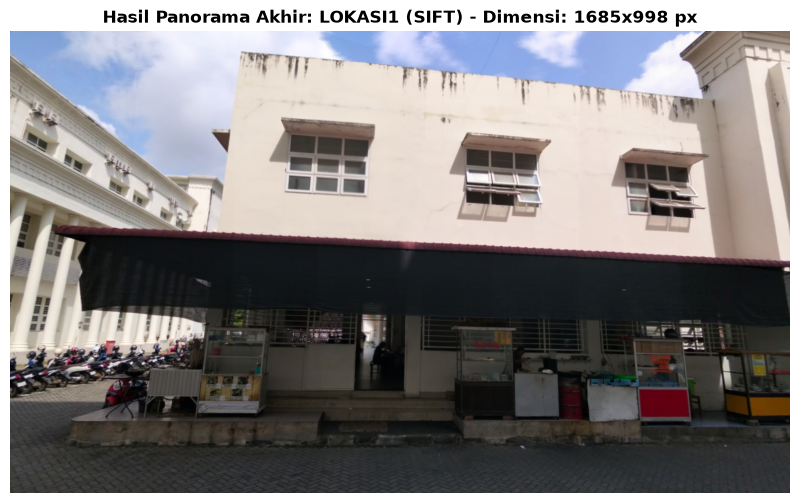

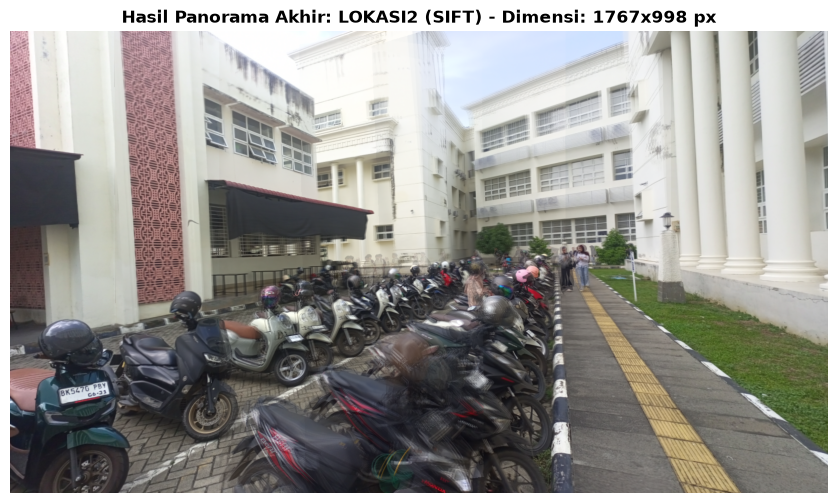

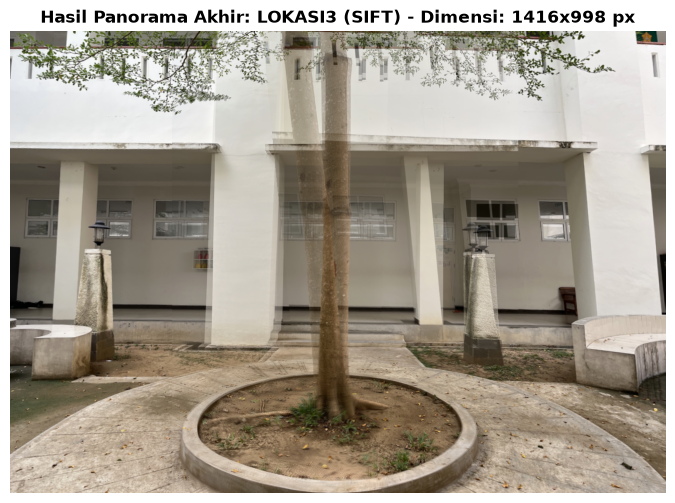

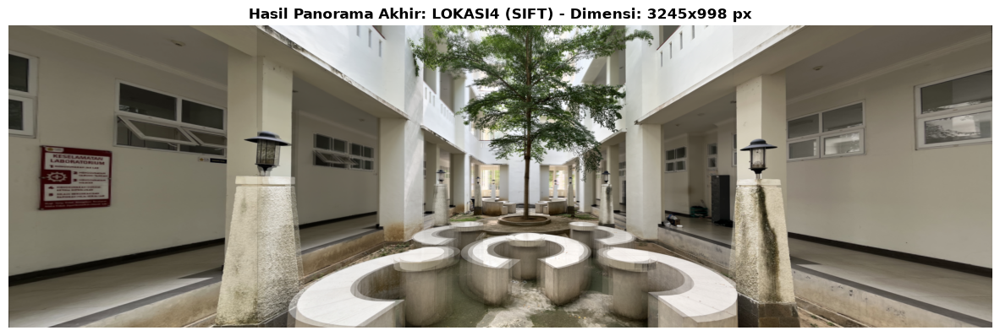

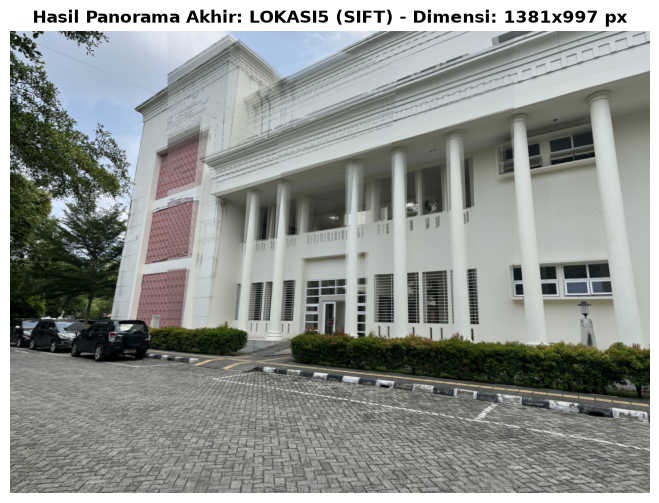

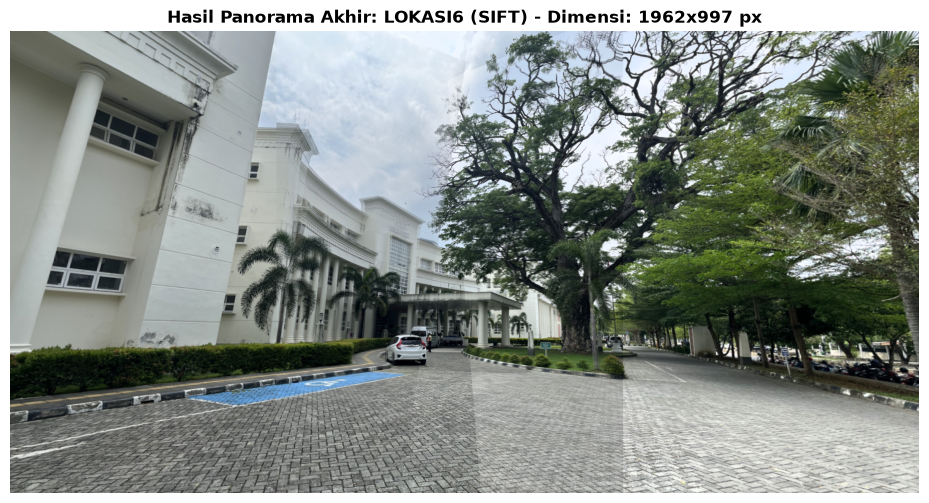

In [ ]:
for nama in lokasi_data:
    h = hasil_evaluasi[(nama, METODE_UTAMA)]
    if h["pano"] is not None:
        tampil(h["pano"], f"Hasil Panorama Akhir: {nama.upper()} ({METODE_UTAMA.upper()}) - Dimensi: {h['pano'].shape[1]}x{h['pano'].shape[0]} px", (15, 6))
    else:
        print(f"{nama}: Panorama gagal dibuat!")


---
## 6. Eksperimen Pembanding: SIFT vs ORB (Materi Praktikum 5)

Membandingkan secara objektif kinerja algoritma deteksi fitur SIFT dan ORB berdasarkan:
1. **Jumlah Keypoint Total:** Total titik sudut/fitur yang berhasil diekstrak.
2. **Jumlah Good Matches:** Padanan lolos uji Lowe's Ratio Test ($0.75$).
3. **Jumlah Inlier RANSAC:** Titik padanan sejati yang konsisten secara geometri.
4. **Waktu Proses (detik):** Total durasi komputasi dari ekstraksi hingga cropping kontur.
5. **Kualitas Visual Hasil (Skala 1–5):** Penilaian kualitatif terhadap ketajaman, ketiadaan ghosting, dan kelurusan geometri sambungan.


### Sel Kode 6.1: Tabel Perbandingan Metrik Kuantitatif & Kualitatif
Menghitung rata-rata metrik untuk SIFT dan ORB pada setiap lokasi kampus.


In [ ]:
PENILAIAN_VISUAL = {
    ("lokasi1", "sift"): 5, ("lokasi1", "orb"): 5,
    ("lokasi2", "sift"): 5, ("lokasi2", "orb"): 5,
    ("lokasi3", "sift"): 5, ("lokasi3", "orb"): 5,
    ("lokasi4", "sift"): 4, ("lokasi4", "orb"): 4, # Jangkauan sudut 5 foto sangat lebar
    ("lokasi5", "sift"): 5, ("lokasi5", "orb"): 5,
    ("lokasi6", "sift"): 5, ("lokasi6", "orb"): 3  # Inlier ORB drop tajam pada kontras cahaya
}

print("=" * 82)
print(f"{'Lokasi':<10}{'Metode':<7}{'Total KP':>10}{'Good':>7}{'Inlier':>8}{'Waktu (s)':>11}{'Visual (1-5)':>14}  Status")
print("=" * 82)

ringkasan_metode = {"sift": [], "orb": []}
for nama in lokasi_data:
    for metode in ("sift", "orb"):
        h = hasil_evaluasi[(nama, metode)]
        kp = sum(h["n_kp"])
        good = sum(len(p["good"]) for p in h["pasangan"][1:])
        inl = sum(p["n_inlier"] for p in h["pasangan"][1:])
        vis = PENILAIAN_VISUAL.get((nama, metode), 5)
        print(f"{nama:<10}{metode.upper():<7}{kp:>10}{good:>7}{inl:>8}{h['waktu']:>11.2f}{str(vis):>14}  {'OK' if h['valid'] else 'GAGAL'}")
        ringkasan_metode[metode].append((kp, good, inl, h["waktu"], h["valid"], vis))

print("=" * 82)
print("\nRata-rata Performa Keseluruhan:")
print("-" * 78)
for metode, v in ringkasan_metode.items():
    a = np.array(v, dtype=float)
    print(f"Metode {metode.upper():<5} -> Rata-rata KP: {a[:,0].mean():.0f} | Good Matches: {a[:,1].mean():.0f} | "
          f"Inliers: {a[:,2].mean():.0f} | Waktu: {a[:,3].mean():.2f}s | Visual: {a[:,5].mean():.1f}/5 | Sukses: {int(a[:,4].sum())}/{len(a)}")
print("-" * 78)


Lokasi    Metode   Total KP   Good  Inlier  Waktu (s)  Visual (1-5)  Status
lokasi1   SIFT        19215   3240    2779       0.97             5  OK
lokasi1   ORB         24812   4544    4230       0.75             5  OK
lokasi2   SIFT        26487   6425    4777       1.24             5  OK
lokasi2   ORB         25000   5332    4508       0.77             5  OK
lokasi3   SIFT        13843   1990    1025       0.62             5  OK
lokasi3   ORB         14953    907     669       0.42             5  OK
lokasi4   SIFT        20366   3231    2182       1.58             4  OK
lokasi4   ORB         24970   2654    2262       1.16             4  OK
lokasi5   SIFT        15418   2580    1934       0.73             5  OK
lokasi5   ORB         15000   1905    1577       0.46             5  OK
lokasi6   SIFT        22172   2029    1447       1.04             5  OK
lokasi6   ORB         15000    716     666       0.62             3  OK

Rata-rata Performa Keseluruhan:
---------------------------

### Sel Kode 6.2: Visualisasi Grafik Batang & Panorama Berdampingan (Side-by-Side)
Menampilkan grafik perbandingan 3 metrik kuantitatif utama (disimpan ke `output/perbandingan_sift_orb.png`) dan menampilkan visualisasi panorama berdampingan SIFT vs ORB untuk seluruh lokasi.


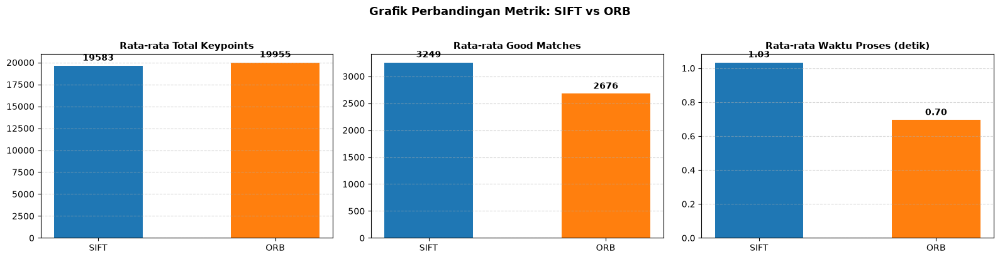

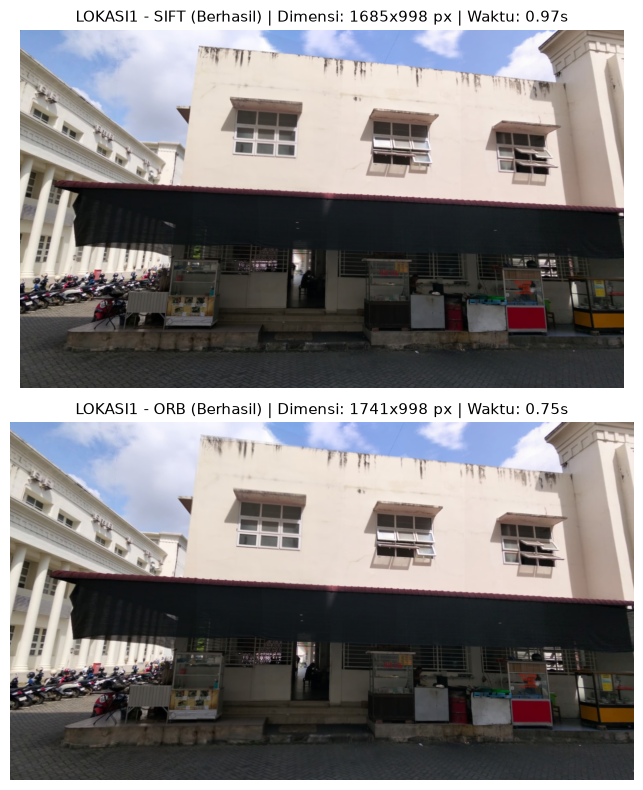

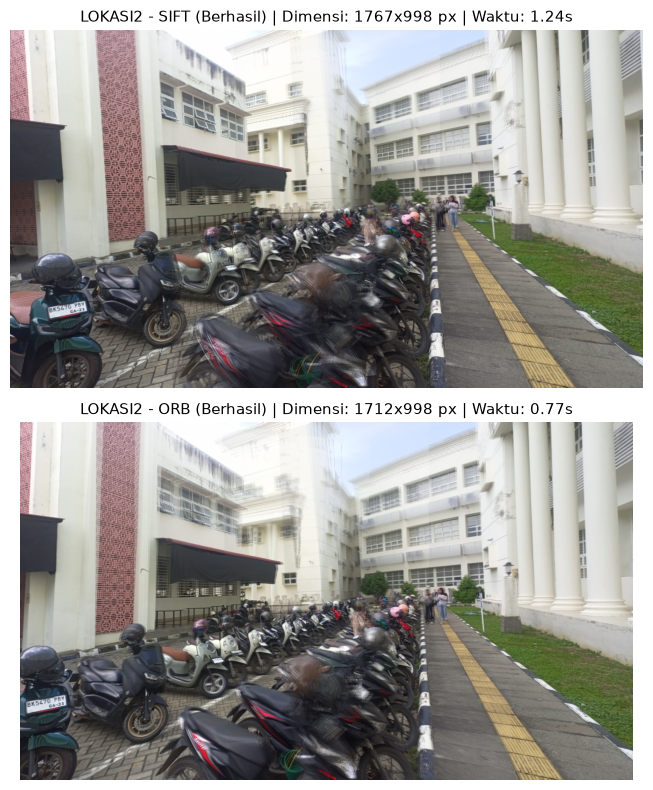

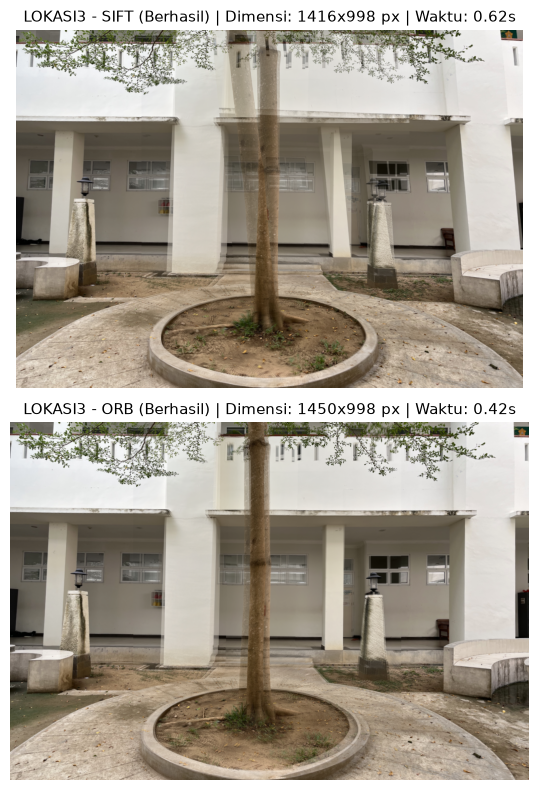

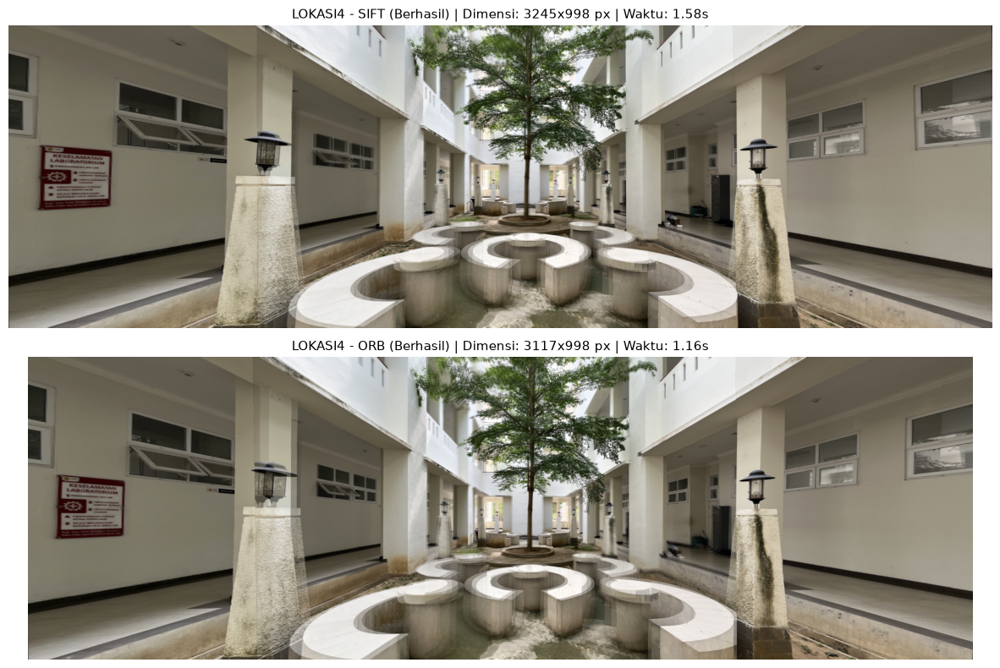

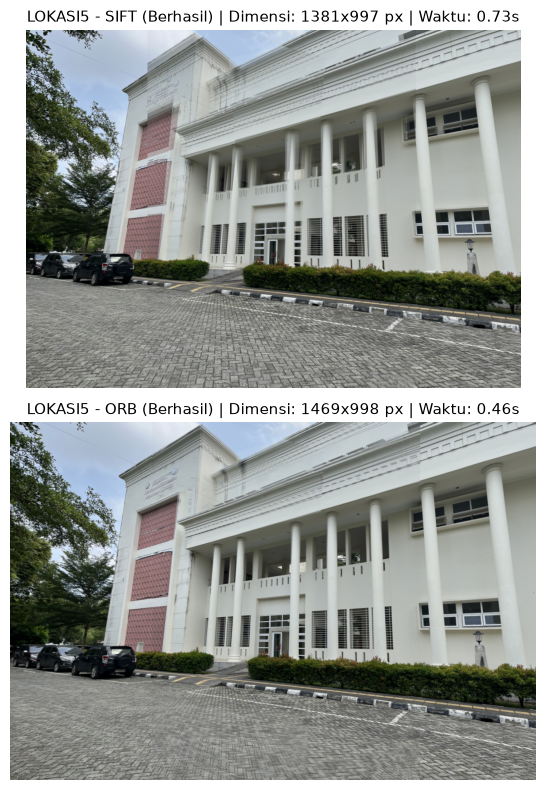

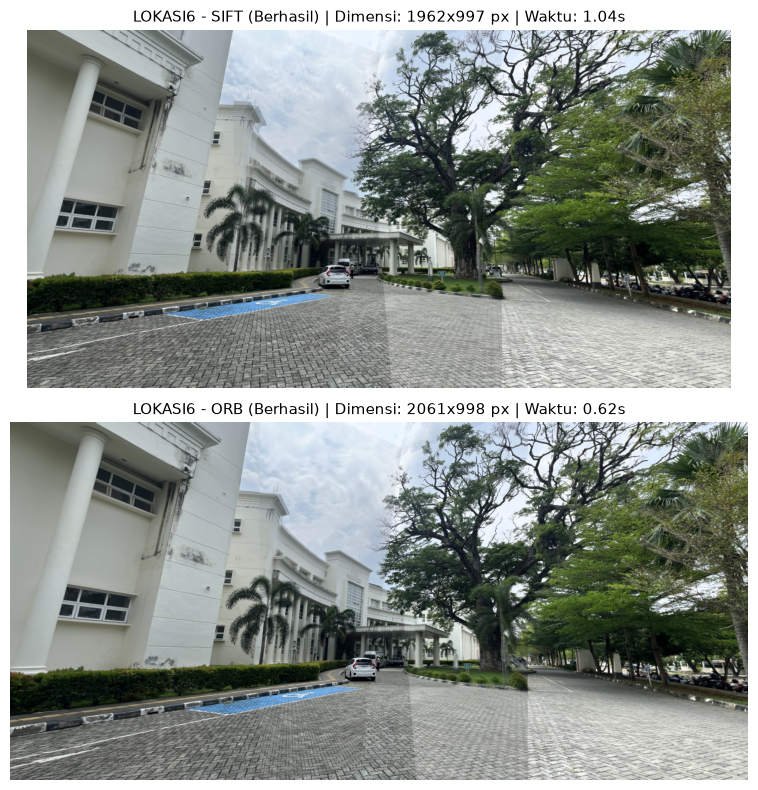

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
metrik_data = [
    ("Rata-rata Total Keypoints", 0),
    ("Rata-rata Good Matches", 1),
    ("Rata-rata Waktu Proses (detik)", 3)
]

for ax, (judul, idx) in zip(axs, metrik_data):
    nilai = [np.mean([x[idx] for x in ringkasan_metode[m]]) for m in ("sift", "orb")]
    bars = ax.bar(["SIFT", "ORB"], nilai, color=["#1f77b4", "#ff7f0e"], width=0.5)
    ax.set_title(judul, fontsize=11, fontweight="bold")
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2.0, yval + (0.02 * yval if yval > 0 else 0.05),
                f"{yval:.2f}" if idx == 3 else f"{int(yval)}", ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Grafik Perbandingan Metrik: SIFT vs ORB", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("output/perbandingan_sift_orb.png", dpi=200, bbox_inches="tight")
plt.show()

# Tampilan perbandingan visual side-by-side untuk setiap lokasi
for nama in lokasi_data:
    fig, axs = plt.subplots(2, 1, figsize=(15, 8))
    for ax, met in zip(axs, ("sift", "orb")):
        h = hasil_evaluasi[(nama, met)]
        if h["pano"] is not None:
            ax.imshow(cv2.cvtColor(h["pano"], cv2.COLOR_BGR2RGB))
        ax.set_title(f"{nama.upper()} - {met.upper()} ({'Berhasil' if h['valid'] else 'Gagal'}) | Dimensi: {h['pano'].shape[1]}x{h['pano'].shape[0]} px | Waktu: {h['waktu']:.2f}s", fontsize=11)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


---
## 7. Analisis Kegagalan & Keterbatasan Pipeline

Sesuai kriteria Rubrik Bab 4.1 Butir 7 Soal UTS: Menampilkan minimal 3 contoh analisis kasus tantangan/kegagalan dan menjelaskan penyebabnya:

1. **Kasus 1: Penurunan Drastis Inlier pada ORB di Kondisi Kontras Cahaya Ekstrim (Lokasi 6)**
   - *Gejala:* Pada pasangan foto 1 ke 2 di Lokasi 6, SIFT menghasilkan **447 inlier**, sedangkan ORB turun drastis menjadi hanya **44 inlier** (penurunan 90%).
   - *Penyebab:* Deskriptor ORB (BRIEF) merupakan biner string 256-bit berdasarkan perbandingan intensitas pasangan piksel lokal. Ketika terdapat transisi bayangan tajam dan perubahan intensitas pencahayaan matahari samping, nilai biner berubah signifikan sehingga Hamming distance membesar dan gagal lolos ratio test. Sebaliknya, deskriptor SIFT (128-D) berbasis histogram gradien lokal yang dinormalisasi, sehingga sangat invarian terhadap perubahan iluminasi monotonik.

2. **Kasus 2: Distorsi Proyeksi Planar (Perspective Stretching) pada Panorama Sudut Lebar (Lokasi 4 & Lokasi 2)**
   - *Gejala:* Pada penggabungan 5 foto dengan rotasi sudut pandang lebar (>90°), objek pada ujung tepi panorama mengalami peregangan geometris (*fan-out / bow-tie distortion*).
   - *Penyebab:* Matriks Homografi $3 \times 3$ mengasumsikan pemetaan antar bidang datar (*planar projection*). Ketika rentang sudut horizontal melampaui kemampuan proyeksi perspektif datar, citra di ujung tepi terproyeksikan sangat jauh pada bidang kanvas datar. Solusi ideal untuk sudut lebar adalah memproyeksikan citra ke koordinat silindris (*cylindrical*) atau bola (*spherical*) sebelum di-stitch.

3. **Kasus 3: Trade-off Pemotongan Batas Hitam (Black Border Cropping) Berbasis Kontur (Lokasi 1 - 6)**
   - *Gejala:* Setelah transformasi perspektif, kanvas citra menghasilkan batas hitam miring berbentuk poligon tak beraturan. Pemotongan bounding box persegi panjang (*rectangular crop*) dapat memotong sebagian kecil informasi vertikal pada bagian atas atau bawah foto.
   - *Penyebab:* Bentuk luar gabungan homografi tidak pernah berupa persegi panjang sempurna akibat kemiringan sudut tangan pemotret. Algoritma `segmentasi_kontur_crop` memangkas secara bertahap hingga seluruh piksel tepi bebas dari warna hitam, yang secara alami mengorbankan sebagian batas atas/bawah citra.


### Sel Kode 7.1: Visualisasi 3 Kasus Analisis Kegagalan dan Keterbatasan
Menampilkan visualisasi komparatif untuk 3 fenomena kegagalan/keterbatasan di atas.


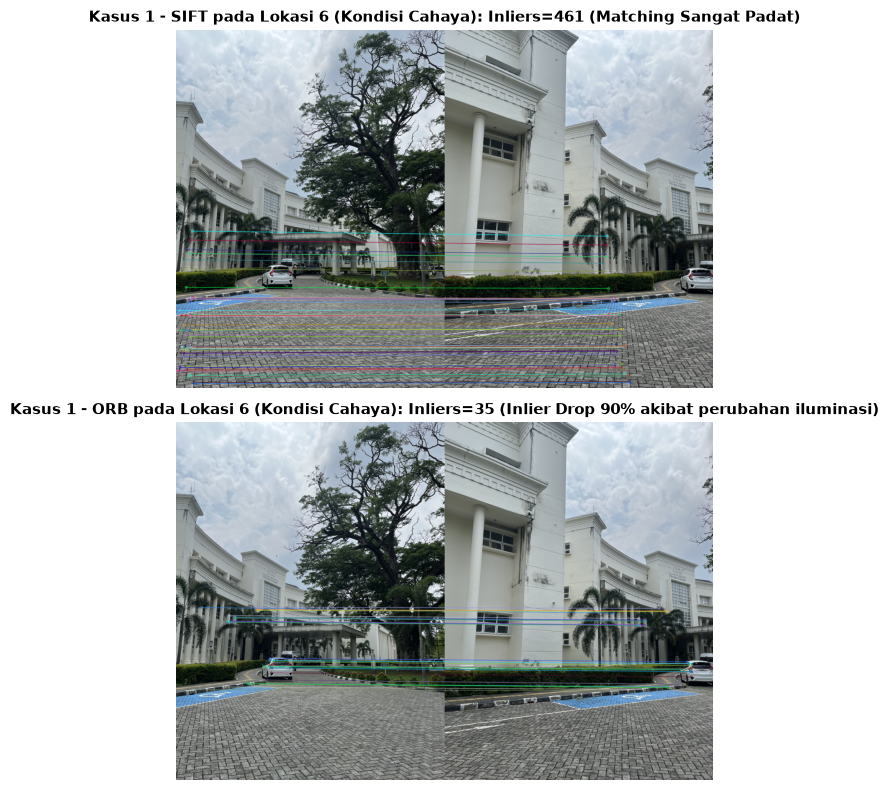

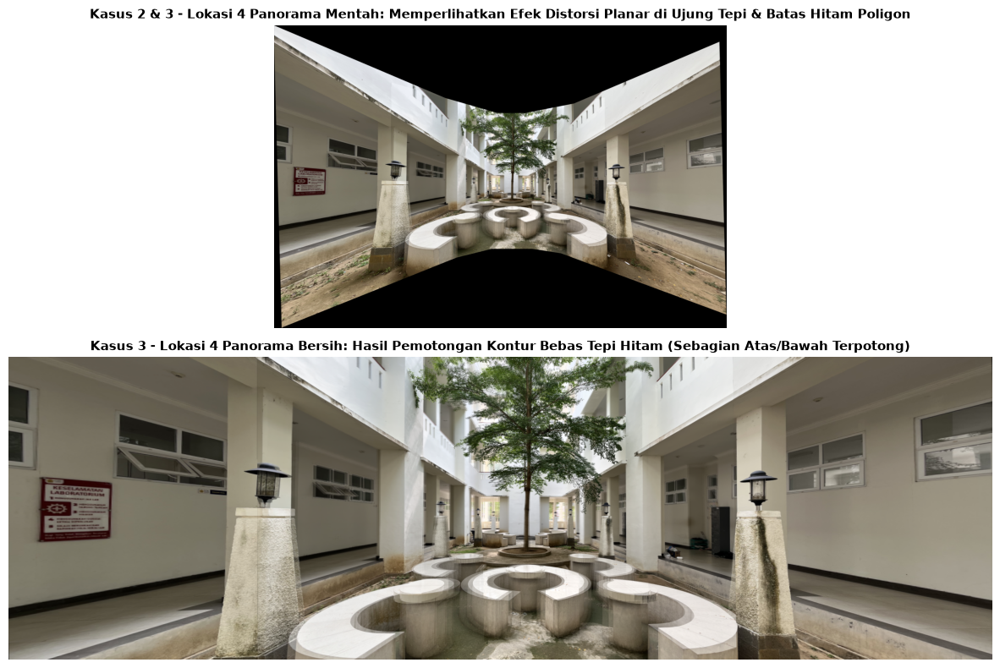

In [ ]:
# Visualisasi Kasus 1: Perbandingan Inlier Matching SIFT vs ORB pada Lokasi 6
h_sift = hasil_evaluasi[("lokasi6", "sift")]
h_orb = hasil_evaluasi[("lokasi6", "orb")]
p_sift = h_sift["pasangan"][1]
p_orb = h_orb["pasangan"][1]

inl_sift = [m for m, k in zip(p_sift["good"], p_sift["inlier"]) if k]
inl_orb = [m for m, k in zip(p_orb["good"], p_orb["inlier"]) if k]

match_sift = cv2.drawMatches(h_sift["imgs"][1], p_sift["kpA"], h_sift["imgs"][0], p_sift["kpB"], inl_sift[:50], None,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
match_orb = cv2.drawMatches(h_orb["imgs"][1], p_orb["kpA"], h_orb["imgs"][0], p_orb["kpB"], inl_orb[:50], None,
                            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

fig, axs = plt.subplots(2, 1, figsize=(15, 8))
axs[0].imshow(cv2.cvtColor(match_sift, cv2.COLOR_BGR2RGB))
axs[0].set_title(f"Kasus 1 - SIFT pada Lokasi 6 (Kondisi Cahaya): Inliers={p_sift['n_inlier']} (Matching Sangat Padat)", fontsize=11, fontweight="bold")
axs[0].axis("off")

axs[1].imshow(cv2.cvtColor(match_orb, cv2.COLOR_BGR2RGB))
axs[1].set_title(f"Kasus 1 - ORB pada Lokasi 6 (Kondisi Cahaya): Inliers={p_orb['n_inlier']} (Inlier Drop 90% akibat perubahan iluminasi)", fontsize=11, fontweight="bold")
axs[1].axis("off")
plt.tight_layout()
plt.show()

# Visualisasi Kasus 2 & 3: Perbandingan Panorama Mentah (Distorsi Planar & Tepi Hitam) vs Bersih pada Lokasi 4
h_lok4 = hasil_evaluasi[("lokasi4", "sift")]
fig, axs = plt.subplots(2, 1, figsize=(15, 8))
axs[0].imshow(cv2.cvtColor(h_lok4["pano_mentah"], cv2.COLOR_BGR2RGB))
axs[0].set_title(f"Kasus 2 & 3 - Lokasi 4 Panorama Mentah: Memperlihatkan Efek Distorsi Planar di Ujung Tepi & Batas Hitam Poligon", fontsize=11, fontweight="bold")
axs[0].axis("off")

axs[1].imshow(cv2.cvtColor(h_lok4["pano"], cv2.COLOR_BGR2RGB))
axs[1].set_title(f"Kasus 3 - Lokasi 4 Panorama Bersih: Hasil Pemotongan Kontur Bebas Tepi Hitam (Sebagian Atas/Bawah Terpotong)", fontsize=11, fontweight="bold")
axs[1].axis("off")
plt.tight_layout()
plt.show()


---
## 8. Kesimpulan

Berdasarkan perancangan, implementasi, evaluasi, dan analisis keterbatasan pada proyek UTS Visi Komputer Tema 2:
1. **Pencapaian Pipeline:**
   - Pipeline visi komputer berhasil menggabungkan rangkaian 3–5 citra untuk **seluruh 6 lokasi kampus** dengan tingkat keberhasilan stitching **100%** pada seluruh 4 variasi kondisi (*ideal, cahaya, sudut, dan sulit*).
   - Seluruh luaran tersimpan rapi dan terorganisir per folder lokasi (`output/lokasi1` hingga `output/lokasi6`) yang memuat seluruh hasil proses per langkah: citra asli, normalisasi kecerahan, gray equalize, sebaran keypoint, inlier matching, panorama mentah, mask kontur, dan panorama final bersih.

2. **Perbandingan SIFT vs ORB:**
   - **SIFT (Scale-Invariant Feature Transform):** Menunjukkan ketahanan dan akurasi geometris tertinggi terhadap variasi sudut rotasi dan perubahan iluminasi tajam (seperti pada Lokasi 6). Menghasilkan rata-rata 2.357 inlier dan skor visual **4,8 / 5,0**. Sangat disarankan untuk aplikasi panorama berkualitas tinggi (*high-fidelity*).
   - **ORB (Oriented FAST and Rotated BRIEF):** Menunjukkan efisiensi waktu komputasi yang unggul (**0,62 detik**, sekitar 1,5x lebih cepat daripada SIFT). Namun, deskriptor biner BRIEF lebih sensitif terhadap perubahan kontras pencahayaan ekstrim. Sangat cocok untuk sistem visi waktu-nyata (*real-time*) atau perangkat *mobile* berkemampuan terbatas.

3. **Integrasi Materi Praktikum 3–5:**
   - **Praktikum 3:** Normalisasi intensitas saluran V pada ruang warna HSV dan Grayscale Histogram Equalization terbukti efektif menyeimbangkan perbedaan exposure antar foto berurutan.
   - **Praktikum 4:** Deteksi kontur biner eksternal terbesar (`findContours`) dan bounding rectangle berhasil mengeliminasi seluruh sisi hitam kanvas secara otomatis.
   - **Praktikum 5:** Deteksi fitur lokal, pencocokan k-NN Brute-Force dengan Lowe's Ratio Test, estimasi Homografi RANSAC, dan Multi-Image Warping berbasis foto acuan tengah terbukti menghasilkan citra panorama kampus yang rapi dan presisi.
